# WSCC9_GFM

Reseau exporte de l'interface g2egrid.

- 24 bus, 18 ligne(s), 6 transfo(s)
- 1 machine(s) synchrone(s), 2 grid-forming, 3 grid-following, 0 bus infini(s)
- f0 = 60 Hz, Sb = 100 MVA

In [1]:
import sys
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import plotly.graph_objects as go


# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from g2egrid.tables import TABLES, Tables, assembler  # noqa: E402

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Construction du reseau

### 1.1 Donnees et assemblage

In [2]:
NOM_RESEAU = "WSCC9_GFM"
F_ZOOM = 5.0

f0 = 60
Sb = 1e+08

# BusType : 1 = slack, 2 = PV, 3 = PQ

# Y_DER : [BusID, Type, Un_V, V_pu, Theta_rad, Pg_W, Qg_var, Pl_W, Ql_var]
Y_DER = [
    (1, 1, 16500, 1.04, 0, 0, 0, 0, 0),
    (2, 2, 18000, 1.025, 0, 165000000, 0, 0, 0),
    (3, 2, 13800, 1.025, 0, 85000000, 0, 0, 0),
    (4, 3, 230000, 1, 0, 0, 0, 0, 0),
    (5, 3, 230000, 1, 0, 0, 0, 125000000, 50000000),
    (6, 3, 230000, 1, 0, 0, 0, 90000000, 30000000),
    (7, 3, 230000, 1, 0, 0, 0, 0, 0),
    (8, 3, 230000, 1, 0, 0, 0, 100000000, 35000000),
    (9, 3, 230000, 1, 0, 0, 0, 0, 0),
    (201, 3, 110000, 1.03, 0, 0, 0, 0, 0),
    (202, 3, 20000, 1, 0, 0, 0, 20400000, 1000000),
    (203, 3, 20000, 1, 0, 0, 0, 0, 0),
    (204, 3, 20000, 1, 0, 0, 0, 550000, 50000),
    (205, 3, 20000, 1, 0, 0, 0, 445000, 50000),
    (206, 3, 20000, 1, 0, 0, 0, 750000, 50000),
    (207, 3, 20000, 1, 0, 0, 0, 565000, 50000),
    (208, 3, 20000, 1, 0, 1200000, 0, 90000, 50000),
    (209, 3, 20000, 1, 0, 0, 0, 605000, 50000),
    (210, 3, 20000, 1, 0, 800000, 0, 675000, 50000),
    (211, 3, 20000, 1, 0, 0, 0, 570000, 50000),
    (212, 3, 20000, 1, 0, 0, 0, 340000, 50000),
    (213, 3, 20000, 1, 0, 0, 0, 205000, 50000),
    (214, 3, 20000, 1, 0, 800000, 0, 40000, 50000),
    (215, 3, 20000, 1, 0, 0, 0, 605000, 50000),
]

# T_Lines_SI : [ID, From, To, Length_km, R_ohm_km, X_ohm_km, B_S_km]
T_Lines_SI = [
    (201, 202, 203, 2.82, 0.501, 0.716, 4.7493e-05),
    (202, 203, 204, 4.42, 0.501, 0.716, 4.7493e-05),
    (203, 204, 205, 0.61, 0.501, 0.716, 4.7493e-05),
    (204, 205, 206, 0.56, 0.501, 0.716, 4.7493e-05),
    (205, 206, 207, 1.54, 0.501, 0.716, 4.7493e-05),
    (206, 208, 209, 1.67, 0.501, 0.716, 4.7493e-05),
    (207, 209, 210, 0.32, 0.501, 0.716, 4.7493e-05),
    (208, 210, 211, 0.77, 0.501, 0.716, 4.7493e-05),
    (209, 211, 212, 0.33, 0.501, 0.716, 4.7493e-05),
    (210, 204, 209, 1.3, 0.501, 0.716, 4.7493e-05),
    (211, 213, 214, 4.89, 0.51, 0.366, 3.172e-06),
    (212, 214, 215, 2.99, 0.51, 0.366, 3.172e-06),
]

# T_Lines_pu : [ID, From, To, Length_km, R_pu, X_pu, B_pu, Un_V, Sb_VA]
T_Lines_pu = [
    (1, 4, 5, 1, 0.01, 0.085, 0.176, 230000, 100000000),
    (2, 4, 6, 1, 0.017, 0.092, 0.158, 230000, 100000000),
    (3, 5, 7, 1, 0.032, 0.161, 0.306, 230000, 100000000),
    (4, 6, 9, 1, 0.039, 0.17, 0.358, 230000, 100000000),
    (5, 7, 8, 1, 0.0085, 0.072, 0.149, 230000, 100000000),
    (6, 8, 9, 1, 0.0119, 0.1008, 0.209, 230000, 100000000),
]

# T_Shunts : [ID, BusID, B_pu]
T_Shunts = []

# T_Transfos : [ID, From, To, Sn_VA, U1_V, U2_V, R_pu, X_pu]
T_Transfos = [
    (1, 1, 4, 100000000, 16500, 230000, 0, 0.0576),
    (2, 2, 7, 100000000, 18000, 230000, 0, 0.0625),
    (3, 3, 9, 100000000, 13800, 230000, 0, 0.0586),
    (200, 5, 201, 100000000, 230000, 110000, 0, 0.05),
    (201, 201, 202, 25000000, 110000, 20000, 0.0016, 0.12),
    (202, 201, 213, 25000000, 110000, 20000, 0.0016, 0.12),
]

# T_IBs : [ID, BusID, Sn_VA, E_pu, theta_deg, R_pu, X_pu]
T_IBs = []

# T_SMs : [ID, BusID, Sn_VA]
T_SMs = [
    (1, 1, 247500000),
]

# T_GFM1s : [ID, BusID, Sn_VA, Vdc_V]
T_GFM1s = [
    (1, 2, 200000000, 40000),
    (2, 3, 130000000, 40000),
]

# T_GFM2s : [ID, BusID, Sn_VA, Vdc_V]
T_GFM2s = []

# T_GFM3s : [ID, BusID, Sn_VA, Vdc_V]
T_GFM3s = []

# T_GFM4s : [ID, BusID, Sn_VA, Vdc_V]
T_GFM4s = []

# T_GFL1s : [ID, BusID, Sn_VA, Vdc_V]
T_GFL1s = [
    (201, 208, 1500000, 40000),
    (202, 210, 1000000, 40000),
    (203, 214, 1000000, 40000),
]

# T_GFL2s : [ID, BusID, Sn_VA, Vdc_V]
T_GFL2s = []

# T_Loads : [ID, BusID, P_W, Q_var, Type]
T_Loads = []

# T_BusDC : [BusID, Type, Un_V, V_pu, Pinj_W]
T_BusDC = []

# T_LinesDC : [ID, From, To, Length_km, R_ohm_km, L_mH_km, C_uF_km]
T_LinesDC = []

# T_ShuntsDC : [ID, BusID, C_pu]
T_ShuntsDC = []

# T_VSCs : [ID, BusAC, BusDC, Mode]
T_VSCs = []

# T_DCDC : [ID, BusDC, Pn_W, Type, P_W]
T_DCDC = []

# T_LoadsDC : [ID, BusDC, P_W, Type]
T_LoadsDC = []

SM_PARAMS = {}

GFM_PARAMS = {}

GFL_PARAMS = {}


In [3]:
# --- assemblage : les tables ci-dessus, puis g2egrid.tables.assembler -------
#
# L'assemblage n'est pas recopie ici. Il l'a ete longtemps, et il y avait donc
# autant de versions que de notebooks : celle qui lisait T_Loads, celle qui
# ignorait PARAMS_PAR_BUS, celle qui ne changeait pas la base des B_pu de
# T_Lines_pu. Lire l'assemblage, c'est lire g2egrid/tables.py.
#
# globals().get : une cellule de donnees ne declare que les tables dont son
# reseau a besoin ; les autres prennent une table vide, exactement comme le
# fait g2egrid.catalogue.charger.
t = Tables(
    **{nom: list(globals().get(nom, [])) for nom in TABLES},
    f0=f0,
    Sb=Sb,
    SM_PARAMS=dict(globals().get("SM_PARAMS", {})),
    GFM_PARAMS=dict(globals().get("GFM_PARAMS", {})),
    GFL_PARAMS=dict(globals().get("GFL_PARAMS", {})),
    PARAMS_PAR_BUS=dict(globals().get("PARAMS_PAR_BUS", {})),
    nom=NOM_RESEAU,
)
net = assembler(t)

n_gfm = sum(len(getattr(t, f"T_GFM{i}s")) for i in (1, 2, 3, 4))
n_rl = sum(1 for r in t.Y_DER if r[7] or r[8])
print(
    f"{NOM_RESEAU} : {len(t.Y_DER)} bus, "
    f"{len(t.T_Lines_SI) + len(t.T_Lines_pu)} ligne(s), "
    f"{len(t.T_Transfos)} transfo(s), {len(t.T_IBs)} bus infini, "
    f"{len(t.T_SMs)} machine(s), {n_gfm} GFM, "
    f"{len(t.T_GFL1s) + len(t.T_GFL2s)} GFL, {n_rl} charge(s) R-L, "
    f"{len(t.T_Loads)} charge(s) speciale(s)"
)
if t.T_BusDC:
    print(
        f"  continu : {len(t.T_BusDC)} noeud(s), {len(t.T_LinesDC)} cable(s), "
        f"{len(t.T_VSCs)} convertisseur(s) a port continu"
    )

WSCC9_GFM : 24 bus, 18 ligne(s), 6 transfo(s), 0 bus infini, 1 machine(s), 2 GFM, 3 GFL, 16 charge(s) R-L, 0 charge(s) speciale(s)


### 1.2 Load flow

In [4]:
lf = net.run_loadflow()
print(
    f"Load flow : converge en {lf.iterations} iterations (mismatch {lf.mismatch:.2e})\n"
)

print(
    f"{'bus':>4} {'|V| [pu]':>10} {'angle [deg]':>12} "
    f"{'P inj [pu]':>12} {'Q inj [pu]':>12}"
)
print("-" * 54)
for b, i in net._bus_index().items():
    print(
        f"{b:>4} {abs(lf.V[i]):>10.4f} {np.degrees(np.angle(lf.V[i])):>12.4f} "
        f"{lf.S[i].real:>12.4f} {lf.S[i].imag:>12.4f}"
    )
print(
    f"\nSomme des injections : P = {lf.S.real.sum():+.4f} pu, "
    f"Q = {lf.S.imag.sum():+.4f} pu  (= pertes)"
)

Load flow : converge en 5 iterations (mismatch 1.29e-12)

 bus   |V| [pu]  angle [deg]   P inj [pu]   Q inj [pu]
------------------------------------------------------
   1     1.0400       0.0000       0.9727       0.3266
   2     1.0250       7.8463       1.6500       0.0988
   3     1.0250       3.3622       0.8500      -0.0949
   4     1.0233      -2.9843      -0.0000       0.0000
   5     0.9879      -5.7770      -1.2500      -0.5000
   6     1.0109      -4.6383      -0.9000      -0.3000
   7     1.0239       2.2431       0.0000       0.0000
   8     1.0144      -0.6699      -1.0000      -0.3500
   9     1.0315       0.6955       0.0000       0.0000
 201     0.9857      -6.4868      -0.0000       0.0000
 202     0.9711     -13.1244      -0.2040      -0.0100
 203     0.9597     -13.8782      -0.0000       0.0000
 204     0.9416     -15.0745      -0.0055      -0.0005
 205     0.9401     -15.1935      -0.0044      -0.0005
 206     0.9390     -15.2759      -0.0075      -0.0005
 207   

## 2. Modele d'etat

Equilibre element par element (Newton sur `[f; g] = 0`), puis assemblage
global : cablage des ports par LFT, elimination des variables algebriques
par complement de Schur.

In [5]:
net.solve_equilibrium()
ss = net.build_state_space()

print(ss)
print(f"\n{len(ss.states)} etats, {len(ss.inputs)} entrees, {len(ss.outputs)} sorties")
print(f"stable : {ss.is_stable()}   max Re(lambda) = {ss.eig().real.max():+.4e}")

print("\nEtats par element :")
seen = []
for s in ss.states:
    owner = s.split(".")[0]
    if owner not in seen:
        seen.append(owner)
for owner in seen:
    noms = [s.split(".", 1)[1] for s in ss.states if s.startswith(owner + ".")]
    print(f"  {owner:<12} {len(noms):>3} : {', '.join(noms)}")

<StateSpace 231 etats, 47 entrees, 187 sorties | max Re(lambda)=+2.760e-11>

231 etats, 47 entrees, 187 sorties
stable : True   max Re(lambda) = +2.7602e-11

Etats par element :
  bus4           2 : vd, vq
  bus5           2 : vd, vq
  bus6           2 : vd, vq
  bus7           2 : vd, vq
  bus8           2 : vd, vq
  bus9           2 : vd, vq
  bus202         2 : vd, vq
  bus203         2 : vd, vq
  bus204         2 : vd, vq
  bus205         2 : vd, vq
  bus206         2 : vd, vq
  bus207         2 : vd, vq
  bus208         2 : vd, vq
  bus209         2 : vd, vq
  bus210         2 : vd, vq
  bus211         2 : vd, vq
  bus212         2 : vd, vq
  bus213         2 : vd, vq
  bus214         2 : vd, vq
  bus215         2 : vd, vq
  L201_202_203   2 : i_d, i_q
  L202_203_204   2 : i_d, i_q
  L203_204_205   2 : i_d, i_q
  L204_205_206   2 : i_d, i_q
  L205_206_207   2 : i_d, i_q
  L206_208_209   2 : i_d, i_q
  L207_209_210   2 : i_d, i_q
  L208_210_211   2 : i_d, i_q
  L209_211_212   2 : i

### 2.1 Tableau modal

Une ligne par valeur propre, triee par partie reelle decroissante (modes les
plus lents d'abord), comme `displayModalAnalysis` en MATLAB : une paire
conjuguee occupe deux lignes. L'index `Mode` est l'indice `k` de `lam[k]`.

| Colonne | Definition |
|---|---|
| `Re`, `Im` | parties reelle [1/s] et imaginaire [rad/s] de la valeur propre |
| `f_und [Hz]` | frequence propre non amortie, `abs(lambda) / 2pi` |
| `f_dam [Hz]` | frequence d'oscillation, `abs(Im) / 2pi` |
| `zeta [%]` | amortissement, `-Re / abs(lambda)` |
| `Etat j`, `%j` | j-ieme etat le plus participant et sa participation `abs(v_ki . w_ik)`, normalisee a 100 % par mode |

In [6]:
lam, Vr = np.linalg.eig(ss.A)
Wl = np.linalg.inv(Vr)
Pf = np.abs(Vr.T) * np.abs(Wl)  # Pf[k, i] : participation de l'etat i au mode k
Pf = Pf / np.maximum(Pf.sum(axis=1, keepdims=True), 1e-30)
top3 = np.argsort(-Pf, axis=1)[:, :3]  # les trois etats les plus participants
k = np.arange(len(lam))

mag = np.abs(lam)
zeta = np.where(mag > 1e-10, -lam.real / np.where(mag > 1e-10, mag, 1.0), 0.0)

T_eig = pd.DataFrame(
    {
        "Re": lam.real,
        "Im": lam.imag,
        "f_und [Hz]": mag / (2 * np.pi),
        "f_dam [Hz]": np.abs(lam.imag) / (2 * np.pi),
        "zeta [%]": 100 * zeta,
    }
)
for j in range(3):
    T_eig[f"Etat {j + 1}"] = [ss.states[i] for i in top3[:, j]]
    T_eig[f"%{j + 1}"] = 100 * Pf[k, top3[:, j]]
T_eig = T_eig.iloc[np.argsort(-lam.real, kind="stable")]
T_eig.index.name = "Mode"



T_eig

,Re,Im,f_und [Hz],f_dam [Hz],zeta [%],Etat 1,%1,Etat 2,%2,Etat 3,%3
Mode,,,,,,,,,,,
184,-7.804864e-11,0.000000,1.242183e-11,0.000000,0.000000,GFM2.theta,52.955658,GFM3.theta,34.087035,SM1.theta,12.957304
186,-1.855323e-01,0.000000,2.952838e-02,0.000000,100.000000,SM1.vpss,98.741326,GFM2.theta,0.307443,SM1.v2,0.231215
187,-5.200486e-01,0.000000,8.276830e-02,0.000000,100.000000,SM1.v1,74.068843,SM1.v2,7.974959,SM1.theta,5.458436
185,-6.772457e-01,0.000000,1.077870e-01,0.000000,100.000000,SM1.theta,27.144908,SM1.phi_1q,22.815000,SM1.v1,16.595414
176,-1.754397e+00,12.539286,2.015128e+00,1.995689,13.856238,SM1.Dwr,33.346097,SM1.Pm,19.876359,SM1.theta,9.535146
...,...,...,...,...,...,...,...,...,...,...,...
5,-9.100637e+05,-376.991118,1.448412e+05,60.000000,99.999991,T200_5_201.i_q,41.423475,T200_5_201.i_d,41.423475,T201_201_202.i_d,4.303668
2,-5.544291e+06,376.991118,8.824013e+05,60.000000,100.000000,GFM3.igq,44.198168,GFM3.igd,44.198168,T3_3_9.i_d,5.801622
3,-5.544291e+06,-376.991118,8.824013e+05,60.000000,100.000000,GFM3.igq,44.198168,GFM3.igd,44.198168,T3_3_9.i_d,5.801622


### 2.2 Carte des valeurs propres

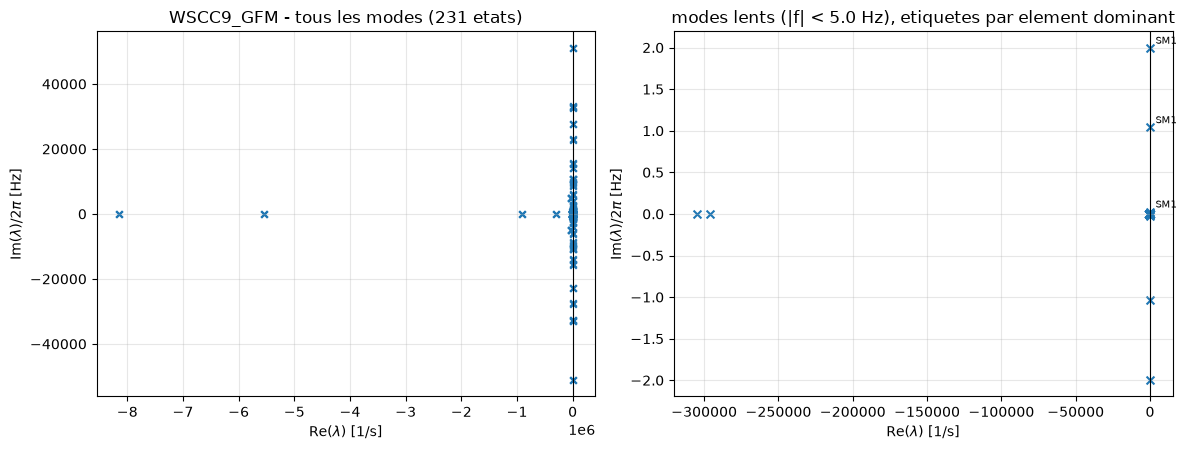

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].scatter(lam.real, lam.imag / (2 * np.pi), s=22, marker="x")
ax[0].axvline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("Re($\\lambda$) [1/s]")
ax[0].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[0].set_title(f"{NOM_RESEAU} - tous les modes ({len(lam)} etats)")
ax[0].grid(True, alpha=0.3)

zoom = np.abs(lam.imag) / (2 * np.pi) <= F_ZOOM
ax[1].scatter(lam[zoom].real, lam[zoom].imag / (2 * np.pi), s=32, marker="x")
for k in np.flatnonzero(zoom & (lam.imag > 1e-6)):
    ax[1].annotate(
        ss.states[top3[k, 0]].split(".")[0],
        (lam[k].real, lam[k].imag / (2 * np.pi)),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax[1].axvline(0.0, color="k", lw=0.8)
ax[1].set_xlabel("Re($\\lambda$) [1/s]")
ax[1].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[1].set_title(f"modes lents (|f| < {F_ZOOM} Hz), etiquetes par element dominant")
ax[1].grid(True, alpha=0.3)

fig.tight_layout()
#plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=T_eig["Re"], y=T_eig["Im"], mode="markers"))

fig.update_xaxes(range=[-1000, 10])
fig.update_yaxes(range=[-10, 1000])
fig.show()